# Lab01 - sprint 2
## Предсказание качества по содержанию спирта
### Модели и метрики

Сравним два прогноза: среднее качество обучающей выборки и линейную зависимость от спирта.
Качество измеряется в баллах. Для регрессии считаем разницу между соседними баллами одинаковой.

Линейная модель:

$$
\hat q = a + bx
$$

Коэффициенты находим методом наименьших квадратов:

$$
b = \frac{\sum_i (x_i-\bar x)(q_i-\bar q)}{\sum_i (x_i-\bar x)^2}
$$

$$
a = \bar q - b\bar x
$$

Ошибки оцениваем по MAE, RMSE и R²:

$$
\mathrm{MAE} = \frac{1}{n}\sum_i |q_i-\hat q_i|
$$

$$
\mathrm{RMSE} = \sqrt{\frac{1}{n}\sum_i (q_i-\hat q_i)^2}
$$

$$
R^2 = 1 - \frac{\sum_i (q_i-\hat q_i)^2}{\sum_i (q_i-\bar q)^2}
$$

MAE и RMSE - в баллах, R² - безразмерный. Основная метрика - RMSE.
Прогнозы не округляем.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
# Backend задаёт Jupyter.
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines
from wine_stats.regression import fit_linear, regression_metrics
print({'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__})
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2})
from wine_stats.plotting import use_style
use_style()

{'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3'}


### Разделение данных

Сначала запускаем `00_data_split.ipynb`. Из train выделяем около 20% групп для validation, seed = 43.
Полные дубликаты остаются в одной части. Test сохраняем для итоговой проверки выбранной модели.

In [2]:
processed = ROOT / 'data/processed'
meta = json.loads((processed / 'alcohol_quality_split.json').read_text())
for name, info in meta['files'].items():
    assert hashlib.sha256((ROOT / 'data/raw' / name).read_bytes()).hexdigest() == info['sha256']
manifest_path = processed / 'alcohol_quality_split.csv'
assert hashlib.sha256(manifest_path.read_bytes()).hexdigest() == meta['manifest_sha256']
manifest = pd.read_csv(manifest_path)
df = load_wines(ROOT / 'data/raw')
pd.testing.assert_frame_equal(manifest, split_wines(df, seed=meta['seed'], test_fraction=meta['test_group_fraction']))
outer_train = manifest['split'].eq('train')
train_data = df.loc[outer_train].reset_index(drop=True)
inner = split_wines(train_data, seed=43, test_fraction=0.2)
roles = manifest.copy()
roles.loc[outer_train, 'split'] = inner['split'].replace({'train': 'fit', 'test': 'validation'}).to_numpy()
assert roles.groupby('group_id')['split'].nunique().max() == 1
assert set(roles['split']) == {'fit', 'validation', 'test'}
assert roles.loc[manifest['split'].eq('test'), 'split'].eq('test').all()
roles.to_csv(processed / 'alcohol_quality_validation_split.csv', index=False)
display(pd.crosstab(roles['split'], roles.wine_type))
fit = df.loc[roles['split'].eq('fit')]
validation = df.loc[roles['split'].eq('validation')]

wine_type,red,white
split,,
fit,1024,3134
test,314,988
validation,261,776


### Обучение и сравнение

Обе модели обучаем на одних данных. Единственный признак - содержание спирта.

In [3]:
baseline = float(fit.quality.mean())
a, b = fit_linear(fit.alcohol.to_numpy(), fit.quality.to_numpy())
rows = []
for part, frame in [('fit', fit), ('validation', validation)]:
    for model, prediction in [('mean', np.full(len(frame), baseline)),
                              ('linear', a + b * frame.alcohol.to_numpy())]:
        rows.append({'split': part, 'model': model, 'n': len(frame),
                     **regression_metrics(frame.quality.to_numpy(), prediction)})
metrics = pd.DataFrame(rows)
print(f'Baseline: {baseline:.4f}; linear: quality = {a:.4f} + {b:.4f} * alcohol')
display(metrics.round(4))
by_type = []
for kind, frame in validation.groupby('wine_type'):
    for model, prediction in [('mean', np.full(len(frame), baseline)),
                              ('linear', a + b * frame.alcohol.to_numpy())]:
        by_type.append({'wine_type': kind, 'model': model, 'n': len(frame),
                        **regression_metrics(frame.quality.to_numpy(), prediction)})
by_type = pd.DataFrame(by_type)
display(by_type.round(4))
tables = ROOT / 'reports/tables'
tables.mkdir(parents=True, exist_ok=True)
metrics.to_csv(tables / 'alcohol_quality_validation_metrics.csv', index=False)
by_type.to_csv(tables / 'alcohol_quality_validation_by_type.csv', index=False)
np.testing.assert_allclose([a,b], np.linalg.lstsq(np.column_stack([np.ones(len(fit)),fit.alcohol]),fit.quality,rcond=None)[0])

Baseline: 5.8158; linear: quality = 2.2940 + 0.3354 * alcohol


,split,model,n,MAE,RMSE,R2
0,fit,mean,4158,0.6918,0.8823,0.0000
1,fit,linear,4158,0.6165,0.7850,0.2085
2,validation,mean,1037,0.6779,0.8586,-0.0000
3,validation,linear,1037,0.6093,0.7676,0.2007


,wine_type,model,n,MAE,RMSE,R2
0,red,mean,261,0.6658,0.8168,-0.0556
1,red,linear,261,0.5719,0.6997,0.2254
2,white,mean,776,0.6820,0.8722,-0.0050
3,white,linear,776,0.6219,0.7892,0.1772


### Графики на validation

Слева - оценки и прогнозы, справа - остатки: наблюдаемое качество минус прогноз.

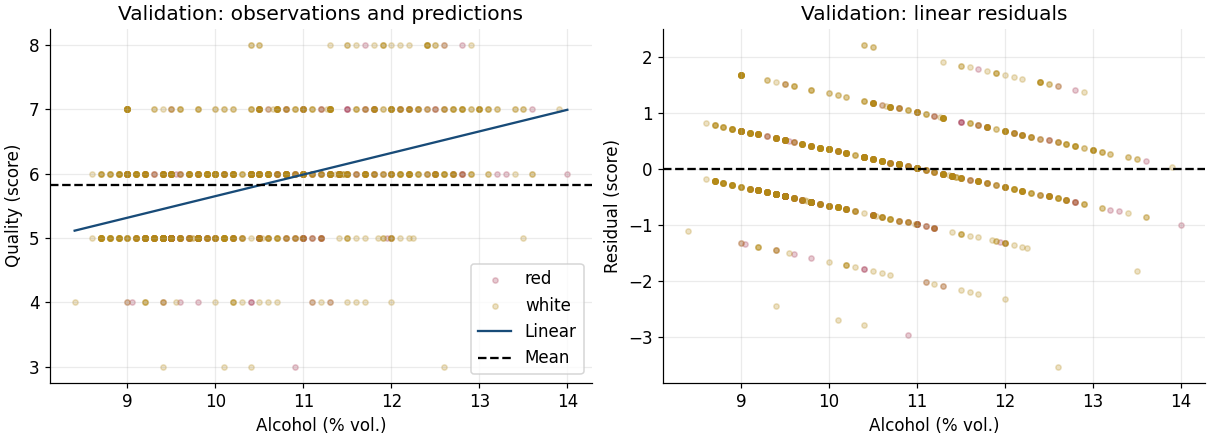

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
colors = {'red': '#a3324d', 'white': '#b58a16'}
for kind, frame in validation.groupby('wine_type'):
    axes[0].scatter(frame.alcohol, frame.quality, s=12, alpha=0.25, color=colors[kind], label=kind)
    axes[1].scatter(frame.alcohol, frame.quality-(a+b*frame.alcohol), s=12, alpha=0.25, color=colors[kind])
x = np.linspace(validation.alcohol.min(), validation.alcohol.max(), 100)
axes[0].plot(x, a+b*x, color='#184b78', label='Linear')
axes[0].axhline(baseline, color='black', linestyle='--', label='Mean')
axes[0].set(xlabel='Alcohol (% vol.)', ylabel='Quality (score)', title='Validation: observations and predictions')
axes[0].legend()
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Alcohol (% vol.)', ylabel='Residual (score)', title='Validation: linear residuals')
figures = ROOT / 'reports/figures'
figures.mkdir(parents=True, exist_ok=True)
figure_path = figures / 'alcohol_quality_validation.png'
fig.savefig(figure_path)
plt.close(fig)
display(Image(filename=str(figure_path)))

## Lab resume

Результаты на validation:

In [5]:
val = metrics.loc[metrics['split'].eq('validation')].set_index('model')
gain = 100 * (1-val.loc['linear','RMSE']/val.loc['mean','RMSE'])
print(f"На validation n={len(validation)}: RMSE baseline={val.loc['mean','RMSE']:.4f}, "
      f"linear={val.loc['linear','RMSE']:.4f}; снижение RMSE={gain:.2f}%.")
print(f"MAE linear={val.loc['linear','MAE']:.4f} балла; R²={val.loc['linear','R2']:.4f}.")
print(f"Наклон {b:.4f} балла на +1 процентный пункт спирта - ассоциация в модели, не причинный эффект.")
print('Одного содержания спирта недостаточно для точного восстановления оценки отдельного вина.')
print('Связь не доказывает, что увеличение спирта само по себе повышает качество.')

На validation n=1037: RMSE baseline=0.8586, linear=0.7676; снижение RMSE=10.60%.
MAE linear=0.6093 балла; R²=0.2007.
Наклон 0.3354 балла на +1 процентный пункт спирта - ассоциация в модели, не причинный эффект.
Одного содержания спирта недостаточно для точного восстановления оценки отдельного вина.
Связь не доказывает, что увеличение спирта само по себе повышает качество.


### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| - | [Модели](01_alcohol_quality_models.ipynb) | - | Baseline, линейная регрессия, метрики ошибок и графики. |